# Brecha digital y rezago escolar en el Perú
Jannys Graciela Navarro · Unidad 2
ENAHO panel, corte 2025, y padrón ESCALE actualizado en 2025. **Problema supervisado elegido: Opción A, rezago escolar.** El no uso de internet queda como descriptivo, no se equipara a exclusión digital efectiva.

Semilla 42. Mantener src, data, notebooks y resultados juntos.

## 1 Preparación
Si faltan bibliotecas, ejecutar en una celda `%pip install -r ../requirements.txt` y reiniciar el kernel. Los originales MINEDU están en `data/raw/MINEDU`; para descargar los ZIP ENAHO consultar `data/raw/INEI/README.md`. Las versiones utilizadas se documentan en `requirements.txt`.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
raiz = Path.cwd()
if raiz.name == "notebooks": raiz = raiz.parent
sys.path.insert(0, str(raiz / "src"))
import pipeline as proyecto
print("Carpeta:", raiz)
print("Semilla:", proyecto.SEED)

Carpeta: C:\Users\grace\Downloads\Proyecto_IA
Semilla: 42


## 2 Limpieza e integración
Se preservan ceros iniciales y nulos de cuestionarios. Se cruzan Personas y Educación 1:1; Vivienda y Sumaria N:1; ESCALE por distrito y área N:1. Se filtran residentes habituales de 6–17 años matriculados en primaria/secundaria y se exige grado válido.

Grado acumulado: P308C en primaria; 6+P308B en secundaria. Edad normativa aproximada=grado acumulado+5. Años de rezago=max(edad−normativa,0). Clase positiva si supera cero; se conserva una sensibilidad >=2 años. Sin fecha de nacimiento usable, no se identifica exactamente la edad al 31 de marzo: este indicador no debe confundirse con la tasa oficial MINEDU de atraso de dos o más años.

Se conserva FACPOB07 para sensibilidad ponderada y FACTOR07 de hogar como referencia; ninguno entra como predictor. La muestra panel no equivale automáticamente a la anual completa.

In [2]:
datos = proyecto.preparar()
display(pd.read_csv(raiz / "resultados/flujo_limpieza.csv"))
display(datos.head())
display(datos.isna().mean().sort_values(ascending=False).head(12))

ETAPA 1 Limpieza e integración


{'filas': 19286, 'conglomerados': 4701, 'distritos': 1186, 'no_uso': 5078, 'prevalencia': np.float64(0.377216633827647), 'con_rezago': 7275, 'criterio_rezago': 'Edad declarada > grado acumulado + 5; aproximación sin fecha de nacimiento al 31 de marzo; sensibilidad >=2 años disponible.', 'cobertura_minedu': np.float64(0.9808669501192575), 'pesos_validos': 19286, 'fechas_padron': {'29-10-2025': 112724}, 'flujo': [{'filtro': 'Base 6 a 17 años', 'n': 24195}, {'filtro': 'Residentes habituales', 'n': 23345}, {'filtro': 'Matriculados primaria o secundaria', 'n': 19286}, {'filtro': 'Respuesta válida sobre uso de internet', 'n': 19286}, {'filtro': 'Grado actual válido para definir rezago', 'n': 19286}]}


,filtro,n
0,Base 6 a 17 años,24195
1,Residentes habituales,23345
2,Matriculados primaria o secundaria,19286
3,Respuesta válida sobre uso de internet,19286
4,Grado actual válido para definir rezago,19286


,CONGLOME,VIVIENDA,HOGAR,CODPERSO,UBIGEO,edad,sexo,lengua_materna,rural,electricidad,...,peso_hogar_referencia,no_uso_internet,grado_acumulado,edad_normativa,anios_rezago,rezago_escolar,rezago_dos_mas,frecuencia_tic,indice_brecha,contexto_encontrado
0,015001,113,11,03,010101,16.0,mujer,castellano,0.0,1.0,...,184.864182,0,11.0,16.0,0.0,0,0,3.0,0.0,1
1,015001,130,11,03,010101,9.0,hombre,castellano,0.0,1.0,...,184.864182,1,4.0,9.0,0.0,0,0,0.0,0.5,1
2,015001,113,11,04,010101,13.0,mujer,castellano,0.0,1.0,...,184.864182,0,8.0,13.0,0.0,0,0,3.0,0.0,1
3,015003,116,11,04,010101,9.0,mujer,castellano,0.0,1.0,...,84.890594,0,3.0,8.0,1.0,1,0,3.0,0.0,1
4,015003,144,11,04,010101,12.0,hombre,castellano,0.0,1.0,...,84.890594,0,7.0,12.0,0.0,0,0,3.0,0.0,1


proporcion_publica      0.019133
latitud_media           0.019133
n_escuelas              0.019133
longitud_media          0.019133
ratio_alumno_docente    0.019133
CONGLOME                0.000000
VIVIENDA                0.000000
HOGAR                   0.000000
UBIGEO                  0.000000
CODPERSO                0.000000
internet_hogar          0.000000
pobreza                 0.000000
dtype: float64

## 3 Clasificación de rezago escolar
Se comparan regresión logística (baseline), Random Forest, XGBoost y LightGBM, tres modelos avanzados expresamente incluidos en la guía; se añade un **MLP con dos capas ocultas implementado en scikit-learn** como comparación adicional. El MLP no usa early stopping con una partición aleatoria interna. Se exploran dos configuraciones por algoritmo.

Se retiran edad, grado, edad normativa, años de rezago y demás componentes del objetivo. El clustering no se utiliza como predictor. Train/test se separan por CONGLOME y train usa GroupKFold de cinco folds; imputación, escalado, one-hot y balance se ajustan en cada fold. Ganador por average precision de CV; test no elige el modelo. Se reportan ROC-AUC, PR-AUC (AP y trapecios), F1 macro, matriz, calibración, sensibilidad ponderada y sensibilidad por distrito.

In [3]:
X, y, train, test, modelo, ganador = proyecto.clasificar(datos)
display(pd.read_csv(raiz / "resultados/clasificacion_seleccion_cv.csv"))
display(pd.read_csv(raiz / "resultados/clasificacion_test.csv"))
print("Ganador seleccionado sin test:", ganador)

ETAPA 2 Clasificación y validación agrupada


Logistica AP CV 0.4043 {'C': 0.1}


RandomForest AP CV 0.3976 {'max_depth': 12, 'min_samples_leaf': 15}


LightGBM AP CV 0.4008 {'num_leaves': 7}


C:\Users\grace\Documents\Codex\2026-10-27\tu-x20\work\packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (180) reached and the optimization hasn't converged yet.
  warnings.warn(


...

MLP AP CV 0.4093 {'alpha': 0.01, 'hidden_layer_sizes': (32, 16)}


XGBoost AP CV 0.402 {'max_depth': 3}


,modelo,parametros,CV_ROC_AUC,CV_PR_AUC_AP,CV_F1_macro,CV_Brier,CV_AP_std
0,MLP,"{""alpha"": 0.01, ""hidden_layer_sizes"": [32, 16]}",0.537486,0.409263,0.517461,0.250058,0.012782
1,Logistica,"{""C"": 0.1}",0.533218,0.404263,0.518258,0.249266,0.010060
2,XGBoost,"{""max_depth"": 3}",0.527450,0.402020,0.512428,0.249663,0.015029
3,LightGBM,"{""num_leaves"": 7}",0.525859,0.400771,0.505291,0.249632,0.014527
4,RandomForest,"{""max_depth"": 12, ""min_samples_leaf"": 15}",0.523181,0.397600,0.511232,0.249174,0.015477


,modelo,ROC_AUC,PR_AUC_AP,PR_AUC_trapecios,F1_macro,accuracy,precision,recall,Brier
0,Logistica,0.538974,0.420525,0.420300,0.526898,0.538807,0.417391,0.492476,0.248603
1,RandomForest,0.523778,0.397224,0.396387,0.520673,0.537751,0.410304,0.452120,0.248831
2,LightGBM,0.528016,0.408191,0.407286,0.516855,0.526135,0.407551,0.502052,0.249250
3,MLP,0.521161,0.409169,0.408710,0.517906,0.544879,0.408392,0.399453,0.248319
4,XGBoost,0.529472,0.408849,0.408081,0.517357,0.528247,0.407513,0.489740,0.249075


Ganador seleccionado sin test: MLP


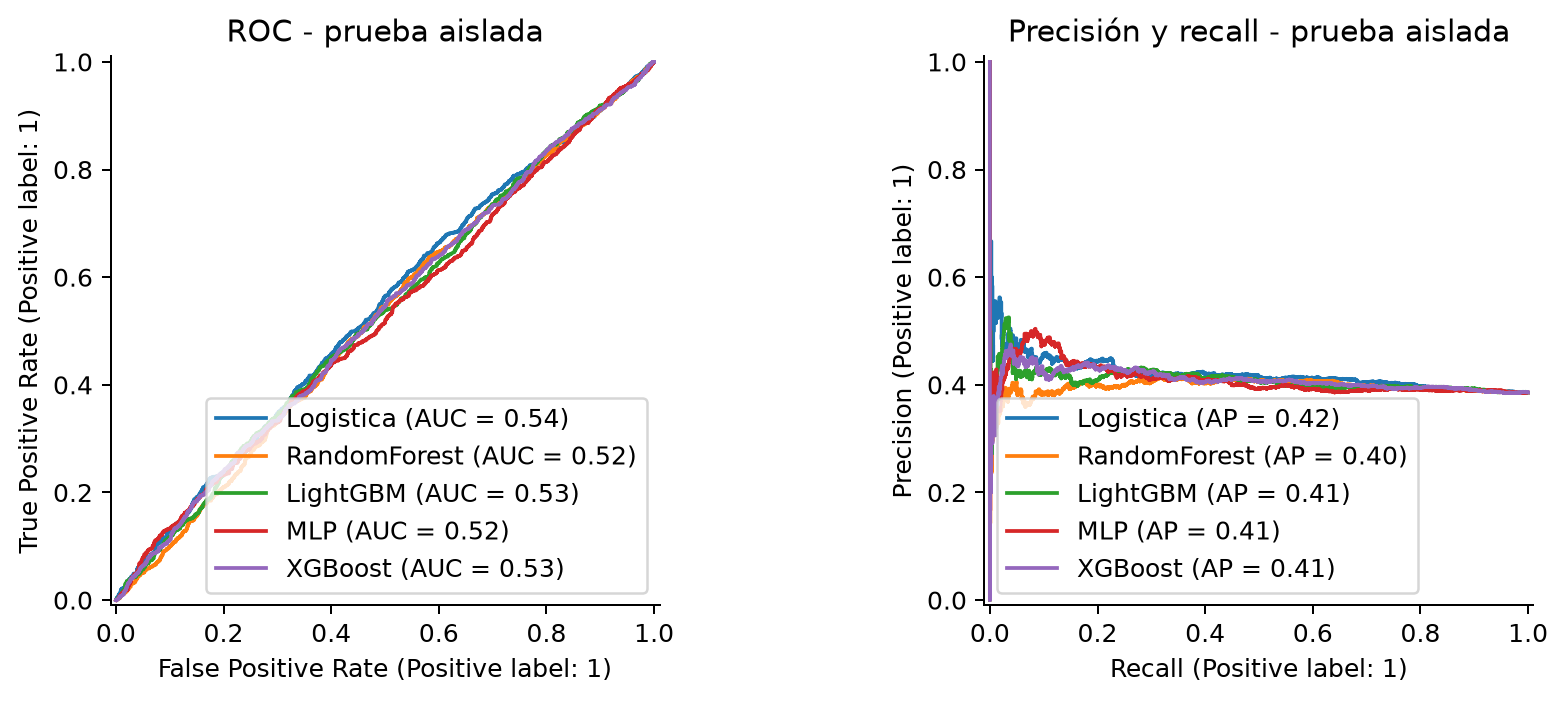

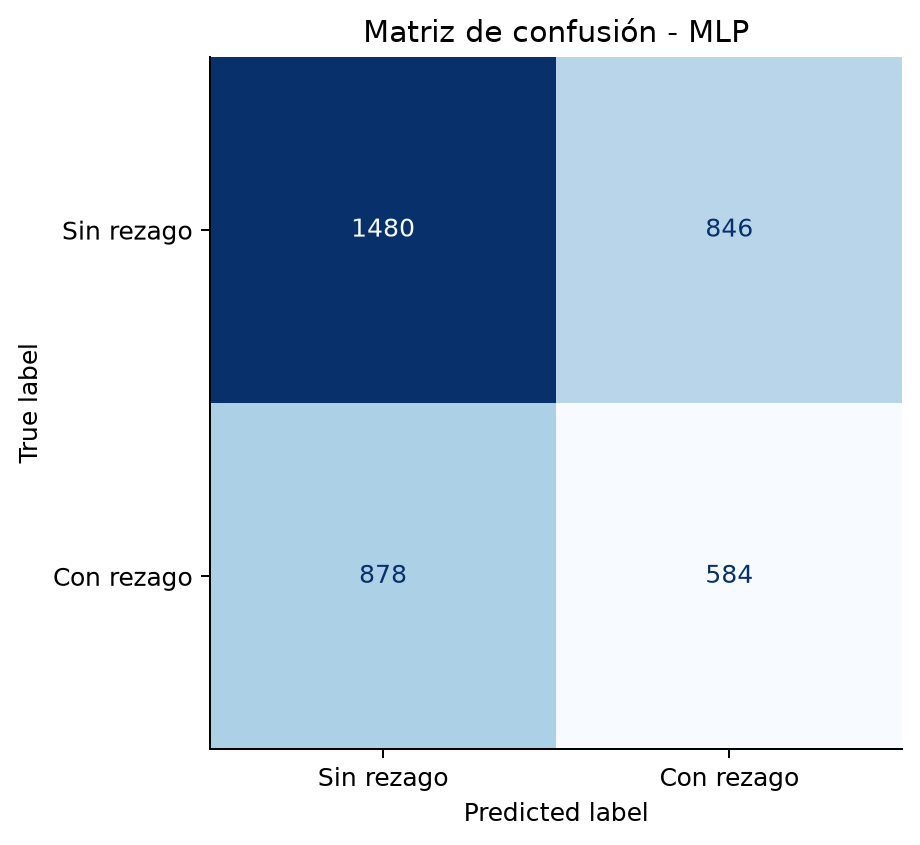

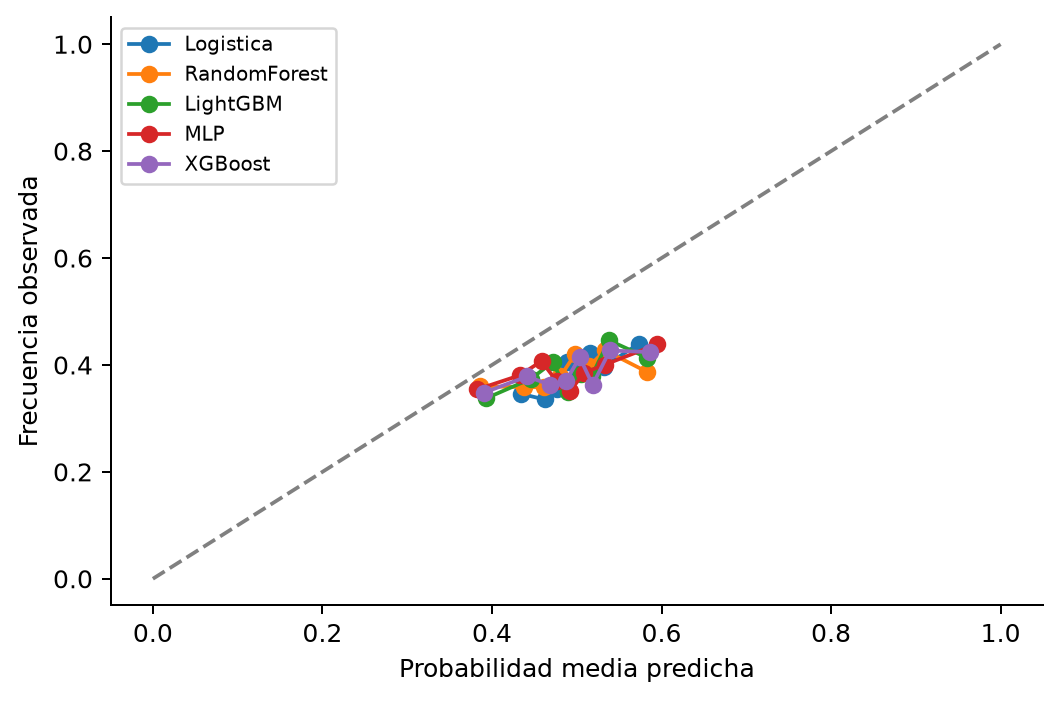

In [4]:
display(Image(filename=str(raiz / "resultados/figuras/curvas_roc_pr.png")))
display(Image(filename=str(raiz / "resultados/figuras/matriz_confusion.png")))
display(Image(filename=str(raiz / "resultados/figuras/calibracion.png")))

## 4 Clustering y perfiles socioeducativos
Se incluyen las variables solicitadas: ingreso/gasto per cápita, ratio alumno/docente, **frecuencia TIC** (P314D: 3 diaria, 2 semanal, 1 mensual/menor; 0 si P314A=no uso), **años de rezago** y servicios básicos.

K-Means y GMM diagonal, k=2…6, misma muestra de train para Silhouette, Davies–Bouldin y Calinski–Harabasz. PCA ajustado solo en train. Nombres y acciones por perfil. Como los años de rezago participan del agrupamiento, diferencias de rezago entre clusters no son evidencia predictiva independiente. No se inyectan clusters en clasificación.

ETAPA 3 Clustering


,algoritmo,k,silhouette,Davies_Bouldin,Calinski_Harabasz
0,KMeans,4,0.294442,1.292506,422.308675
1,KMeans,2,0.287477,1.517859,674.165588
2,KMeans,3,0.286646,1.442061,494.991090
3,GMM,3,0.282538,1.678887,355.498854
4,GMM,2,0.281485,1.566922,634.653309
5,GMM,4,0.213465,1.785591,382.266707
6,GMM,5,0.200937,1.581583,308.215038
7,KMeans,5,0.195411,1.599312,398.417762
8,KMeans,6,0.190156,1.577838,358.774417
9,GMM,6,0.130500,2.687243,299.086402


,cluster,frecuencia_tic,anios_rezago,rural,electricidad,internet_hogar,log_gasto_pc_mensual,log_ingreso_pc_mensual,miembros_hogar,altitud,ratio_alumno_docente,proporcion_publica,no_uso_internet,rezago_escolar,n,perfil_descriptivo,accion_propuesta
0,0,1.199430,0.531814,0.867047,0.000000,1.0,5.872510,5.919405,5.508072,1416.476117,11.962873,0.938300,0.533713,0.433048,1053,"Rural, conectividad doméstica alta, log del ga...",Revisar barreras de uso efectivo y acompañamiento
1,1,2.363991,0.421408,0.011432,0.999740,1.0,6.536337,6.682489,4.758725,772.258660,17.689817,0.486235,0.168182,0.369620,11547,"Urbano, conectividad doméstica alta, log del g...",Revisar necesidades pedagógicas y casos de rezago
2,2,1.031325,0.543373,0.660241,0.608434,0.0,5.944899,5.898140,5.124096,964.238814,14.053581,0.833111,0.613253,0.418072,830,"Rural, conectividad doméstica limitada, log de...",Verificar acceso y ofrecer alternativas fuera ...
3,3,1.741803,0.428791,0.905396,1.000000,1.0,6.001166,6.078670,4.810280,2209.616771,10.385423,0.981243,0.352630,0.376366,5856,"Rural, conectividad doméstica alta, log del ga...",Revisar barreras de uso efectivo y acompañamiento


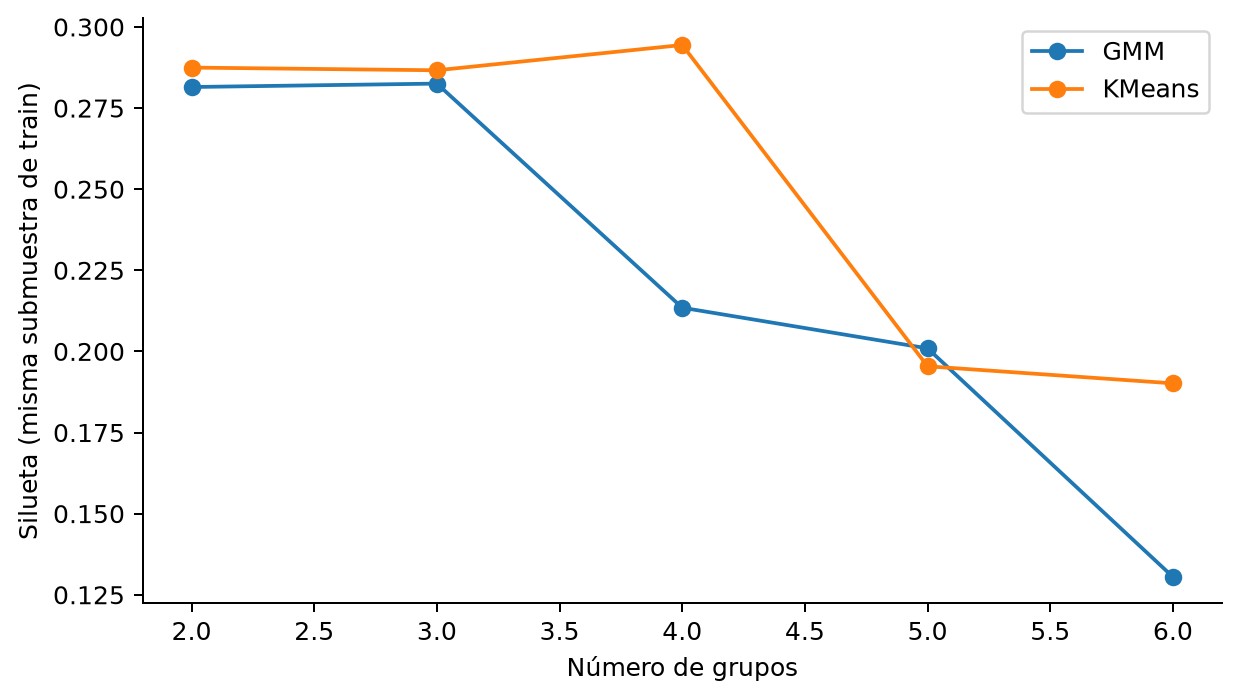

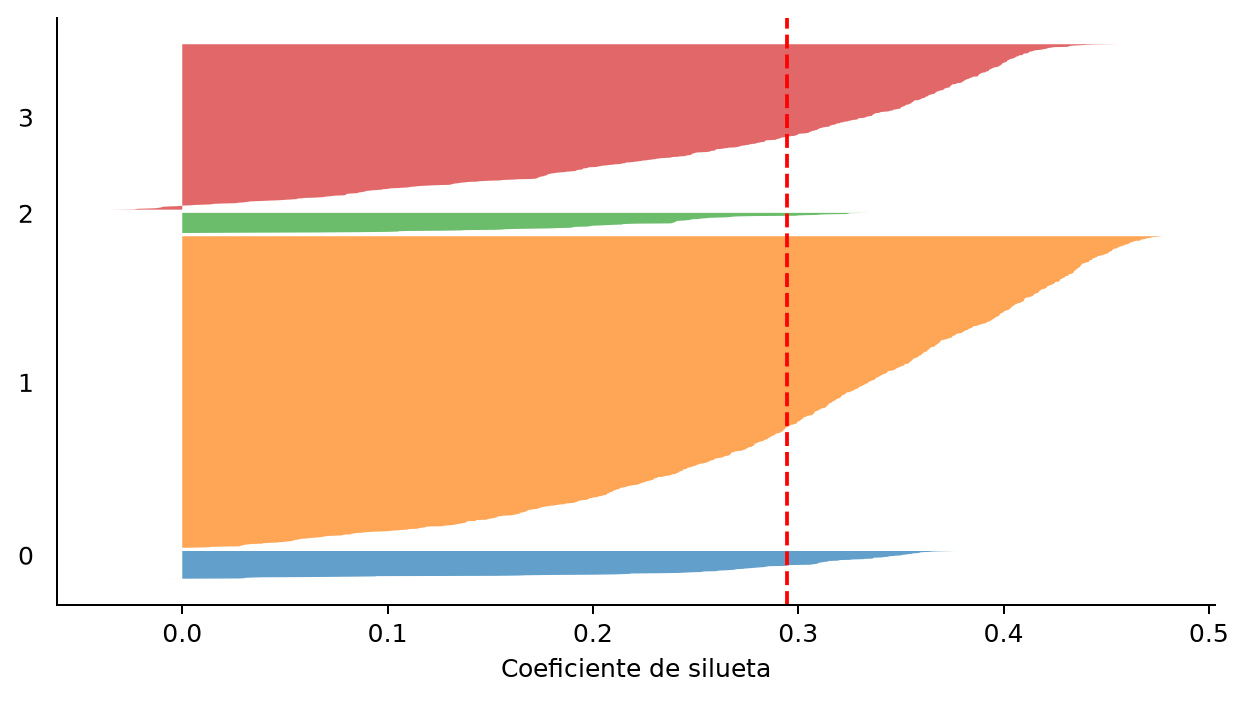

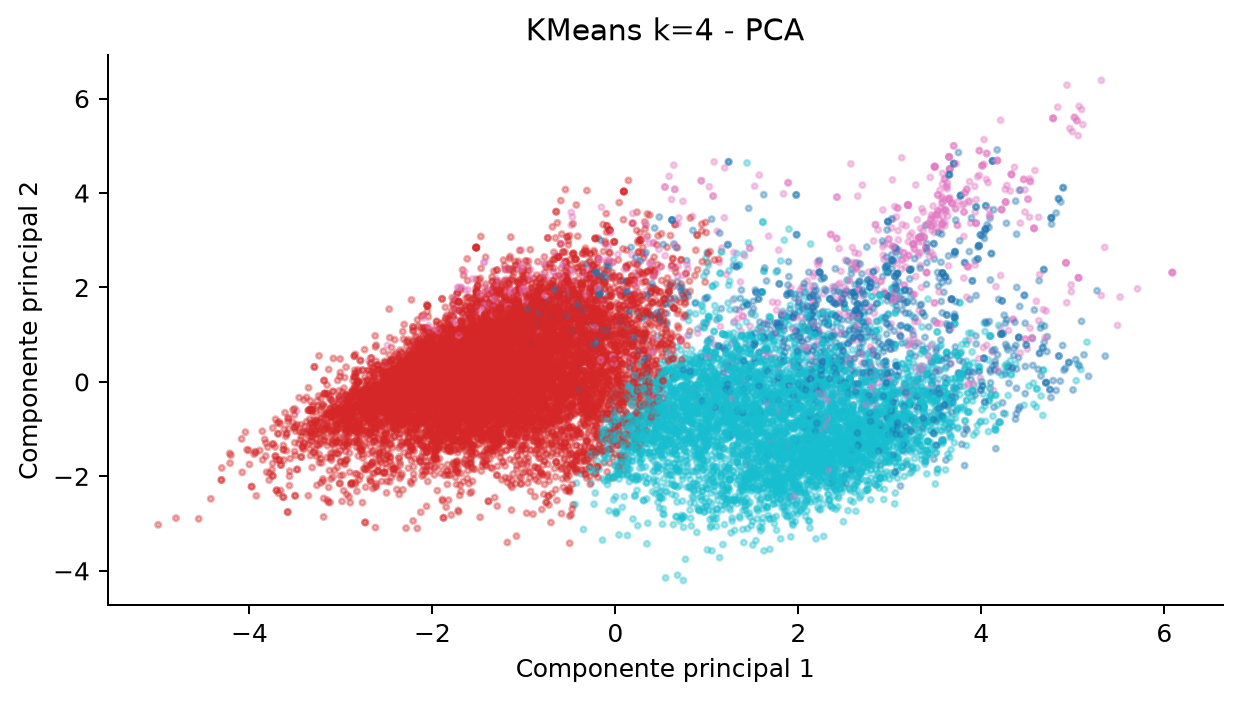

In [5]:
proyecto.clustering(datos, train, test)
display(pd.read_csv(raiz / "resultados/clustering_comparacion.csv"))
display(pd.read_csv(raiz / "resultados/perfiles_clusters.csv"))
display(Image(filename=str(raiz / "resultados/figuras/seleccion_clusters.png")))
display(Image(filename=str(raiz / "resultados/figuras/siluetas.png")))
display(Image(filename=str(raiz / "resultados/figuras/clusters_pca.png")))

## 5 Regresión complementaria del sílabo
Ridge y Random Forest Regressor estiman un índice operativo de falta de uso y conexión doméstica. Es una escala de tres valores, no un índice continuo oficial: **no se presenta como cumplimiento de la Opción B**. La Opción A de rezago es el problema principal, suficiente según la guía. Ambos componentes del índice se excluyen de X. Se reportan MAE, RMSE, R² y residuos.

ETAPA 4 Regresión complementaria del índice


,modelo,MAE,RMSE,R2
0,Ridge,0.184856,0.231742,0.216003
1,RandomForestRegressor,0.183424,0.231633,0.216739


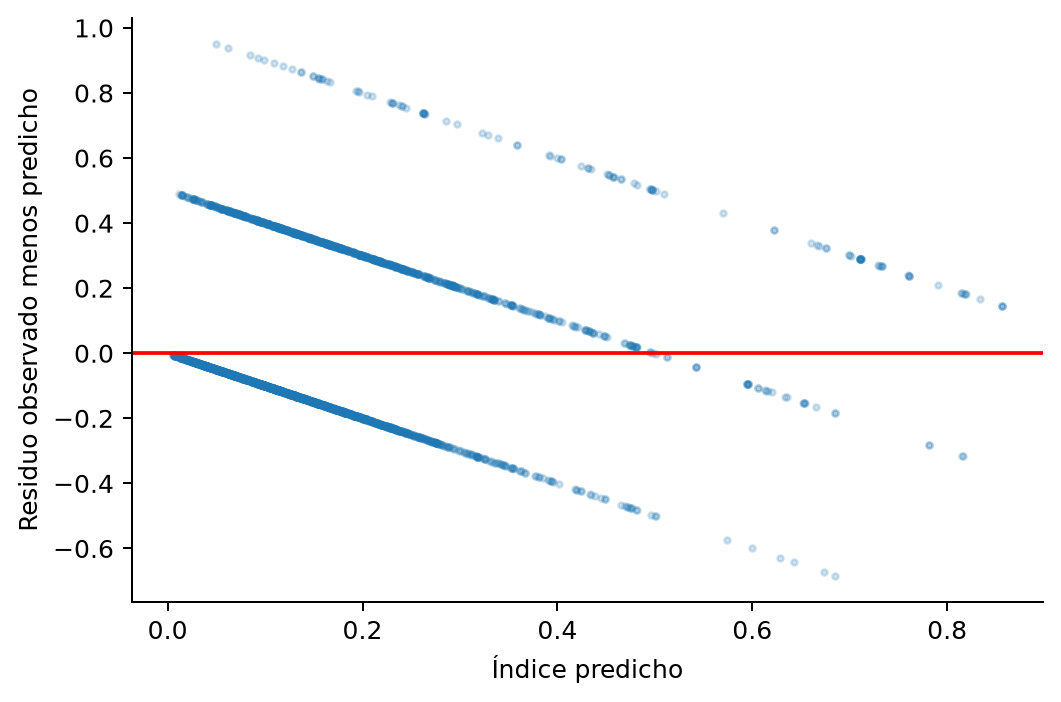

In [6]:
proyecto.regresion(datos, train, test)
display(pd.read_csv(raiz / "resultados/regresion_test.csv"))
display(Image(filename=str(raiz / "resultados/figuras/residuos_regresion.png")))

## 6 SHAP del ganador de rezago
Beeswarm con diez características, dos dependencias (conexión/lengua y ratio/ruralidad) y dos waterfall de casos extremos correctamente clasificados. Fondo tomado solo de train. Se muestran unidades originales de las variables numéricas y se verifica aditividad. Los colores de las dependencias permiten explorar heterogeneidad; no son prueba causal ni valores formales de interacción.

ETAPA 5 SHAP


C:\Users\grace\Documents\Codex\2026-10-27\tu-x20\work\packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,variable,SHAP_abs_medio
0,proporcion_publica,0.019849
1,altitud,0.017903
2,latitud_media,0.014638
3,sexo_mujer,0.013354
4,log_ingreso_pc_mensual,0.011088
5,longitud_media,0.010665
6,rural,0.010040
7,log_gasto_pc_mensual,0.009262
8,miembros_hogar,0.009015
9,n_escuelas,0.008642


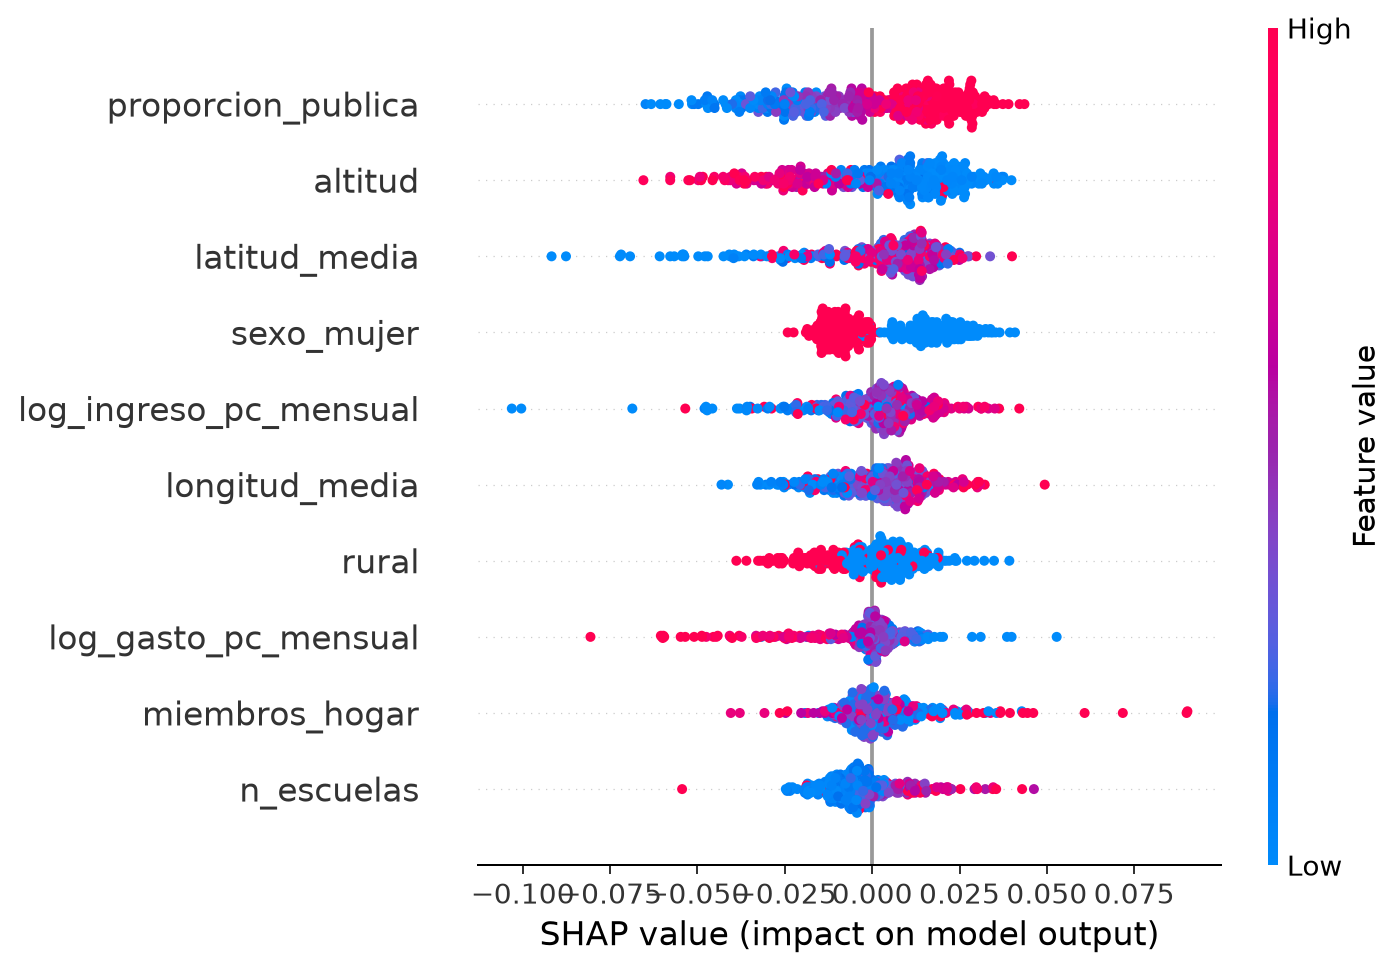

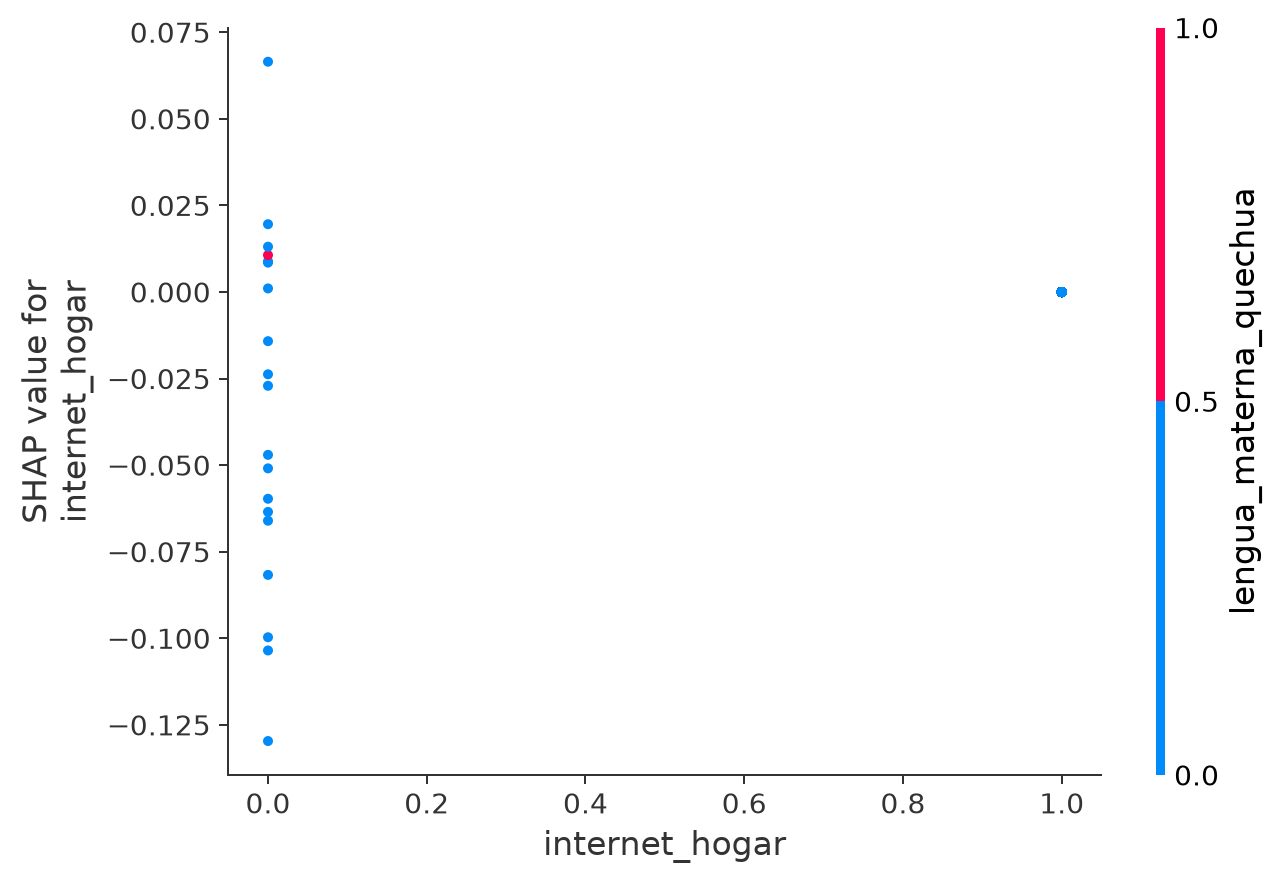

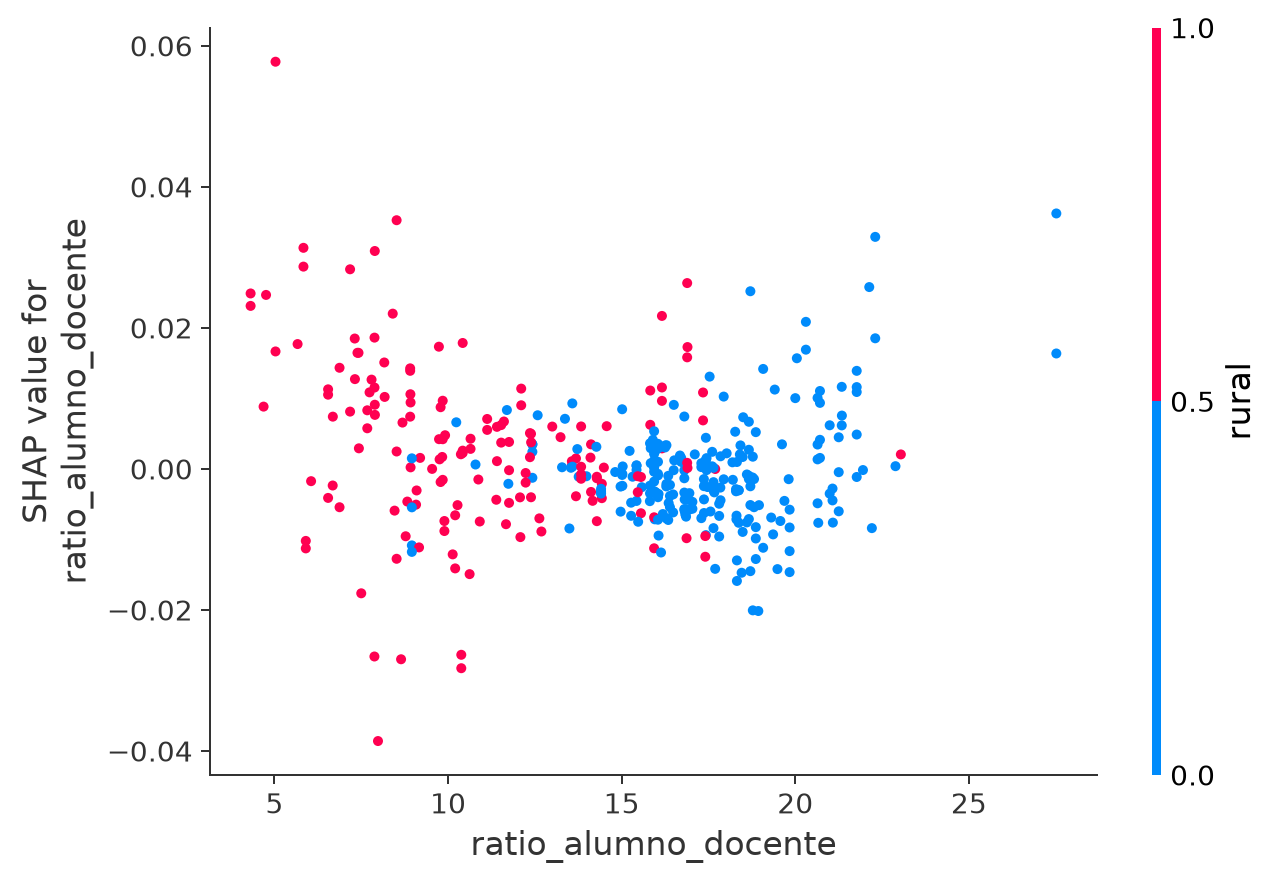

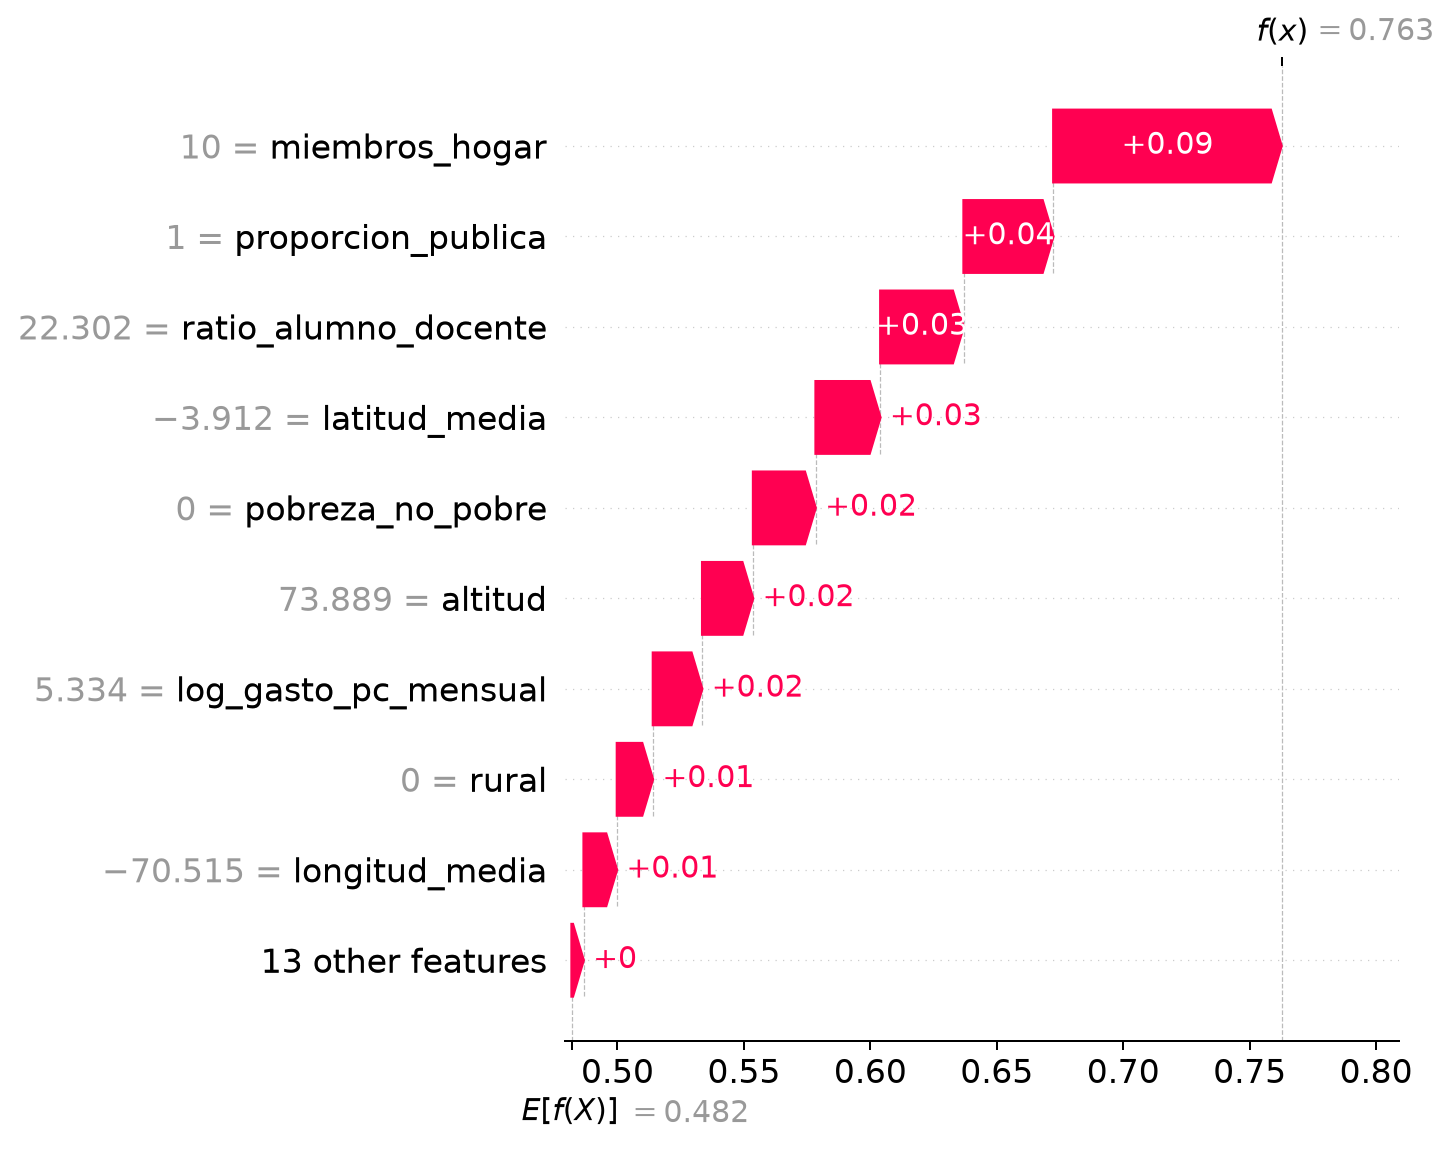

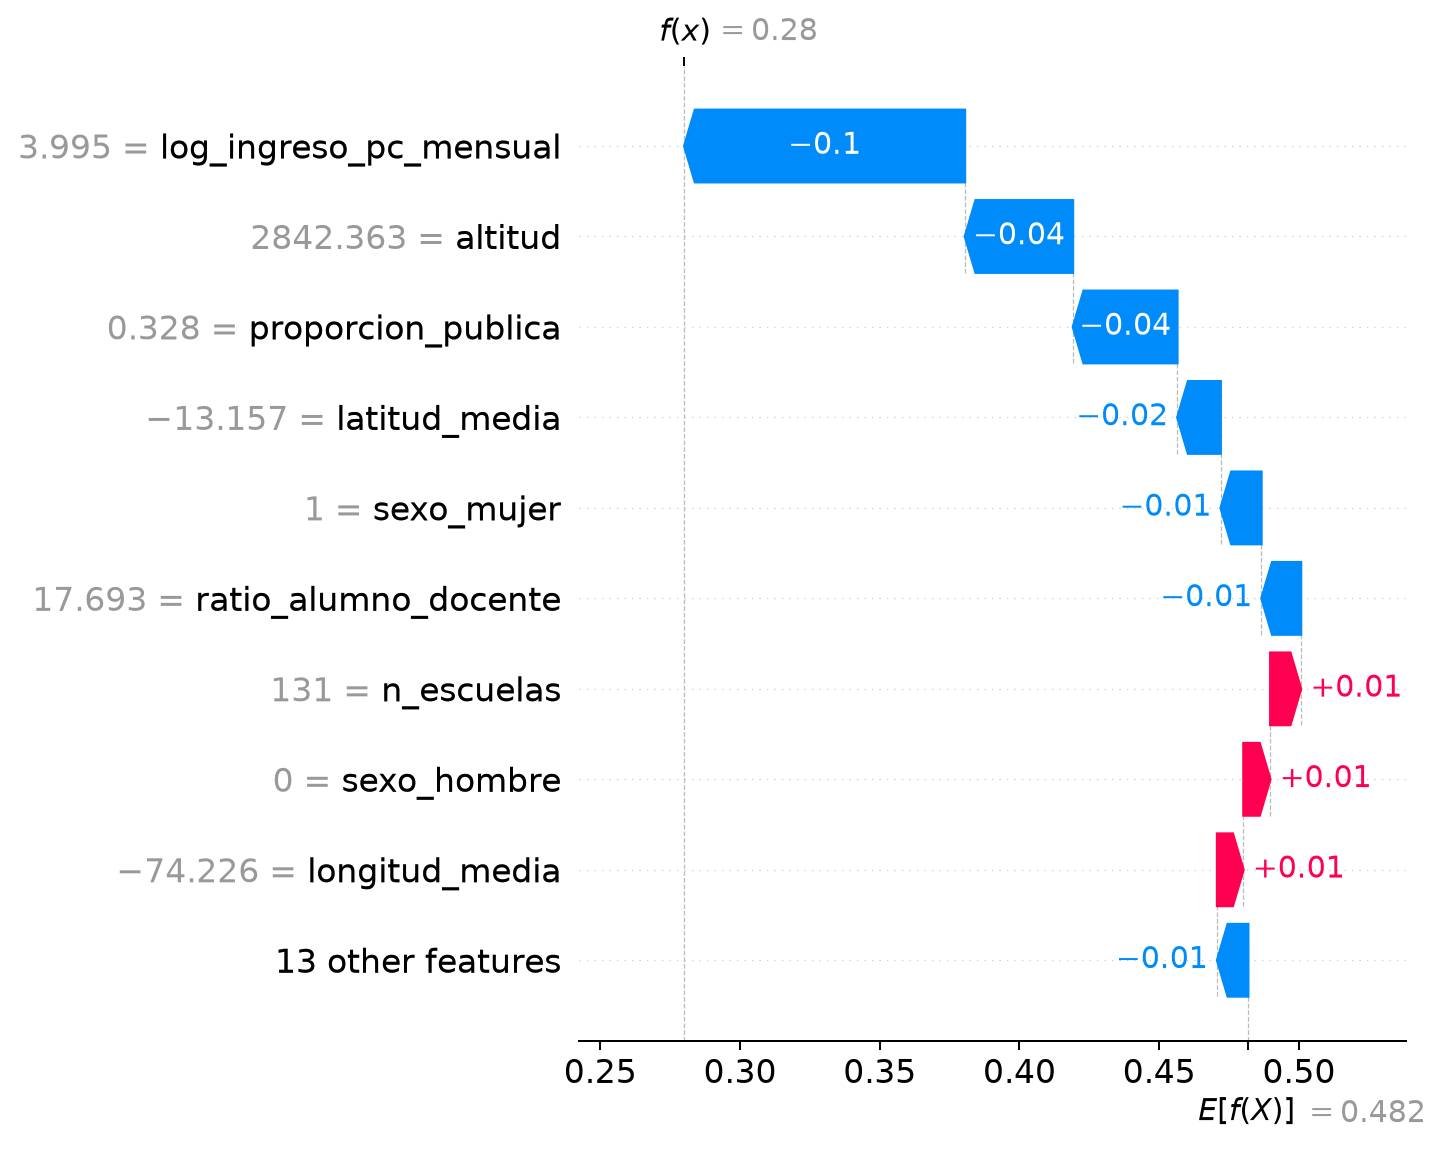

In [7]:
proyecto.explicar(datos, X, y, train, test, modelo, ganador)
display(pd.read_csv(raiz / "resultados/shap_importancia.csv").head(10))
for nombre in ["shap_beeswarm", "shap_dependencia_1", "shap_dependencia_2", "shap_caso_alto", "shap_caso_bajo"]:
    display(Image(filename=str(raiz / f"resultados/figuras/{nombre}.png")))

## 7 Revisión de requisitos y defensa
Consultar AUDITORIA_GUIA_PUNTO_POR_PUNTO.md y el informe. Se entregan CSV/Parquet final, diccionario, fuentes originales, tablas intermedias, código y todos los resultados. Los ZIP originales de Matrícula y Docentes contienen HTML inválido: TALUM y TDOC se toman del padrón, con su imputación documentada.

No hay notas escolares; se modela rezago observado por edad y grado, no notas ni impacto causal de conectividad. Validar fechas, ponderadores y generalización antes de aplicar el modelo fuera de esta muestra.

In [8]:
resumen = json.loads((raiz / "resultados/resumen_clasificacion.json").read_text(encoding="utf-8"))
print("Intersección de conglomerados:", resumen["interseccion_grupos"])
print("Métricas finales:", resumen["test_ganador"])
print("Sensibilidad espacial:", resumen["sensibilidad_separacion_distrito"])
print("Ejecución completa del notebook.")

Intersección de conglomerados: 0
Métricas finales: {'modelo': 'MLP', 'ROC_AUC': 0.5211606028561917, 'PR_AUC_AP': 0.40916913454702164, 'PR_AUC_trapecios': 0.4087097179812993, 'F1_macro': 0.5179056332554957, 'accuracy': 0.5448785638859557, 'precision': 0.4083916083916084, 'recall': 0.399452804377565, 'Brier': 0.24831924394473318}
Sensibilidad espacial: {'ROC_AUC': 0.5282474532101398, 'PR_AUC_AP': 0.3970671104476633, 'PR_AUC_trapecios': 0.3962984132197862, 'F1_macro': 0.5049340476285068, 'accuracy': 0.5059445178335535, 'precision': 0.40110395584176634, 'recall': 0.6055555555555555, 'Brier': 0.2543498580263903}
Ejecución completa del notebook.


## Lectura final de resultados
El MLP fue seleccionado por AP de validación, pero su ROC-AUC de prueba es aproximadamente 0.521 y el intervalo incluye 0.5. **No se demostró utilidad predictiva para priorizar estudiantes.** La revisión entrega un análisis metodológico y descriptivo, con límites explícitos. Las métricas anteriores de no uso de internet no se reutilizan como métricas de rezago.

Revisar la auditoría de 34 puntos y las limitaciones de las fuentes antes de entregar.